# VisionDev distortion tagger v2: training, evaluation and inference

The tagger is a small YOLO11n detector that looks at an image and says which **distortions** it contains:
`blur`, `noise`, `pixelate`, `jpeg`. In VisionDev it is used to tag the images a CIFAR-10 CNN gets wrong.

The tagger that shipped with the project (`best.pt` from the original repo) was trained on 512 px DIV2K crops.
On 32x32 CIFAR images it detects almost nothing, so its tags carried no information.
This notebook documents the **retrained v2 tagger**: how faults are injected, how the model was trained,
how accurate it is, and what its inference looks like.

**Sections**
1. How faults are added to an image (the recipe)
2. The training set
3. Training run (40 epochs, from scratch)
4. Accuracy: old tagger vs new tagger (four tests)
5. Inference examples
6. What the results do and do not say

Everything below is executed; the outputs are stored in this notebook. Training itself is not re-run here
(it takes about 40 minutes on Apple MPS if nothing else is using the GPU; the logged run took 98 minutes because other jobs shared it); the notebook reads the saved logs, weights and eval JSONs.

In [1]:
import json, sys, inspect
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
from torchvision import datasets
from ultralytics import YOLO

import os
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (ROOT / "visiondev").exists(), "run this notebook from visiondev_v2/ or visiondev_v2/notebooks/"
sys.path.insert(0, str(ROOT))
from visiondev.tagger import recipe
from visiondev.tagger.recipe import FAULTS, make_sample, apply_fault

RES = ROOT / "results" / "tagger"   # saved results of the real training run
cifar_test = datasets.CIFAR10(root=os.environ.get("CIFAR_ROOT", str(ROOT / "data")), train=False, download=True)
WEIGHTS = ROOT / "weights" / "tagger_v2.pt"
COLORS = {"blur": (230, 80, 80), "noise": (60, 160, 60), "pixelate": (60, 90, 220), "jpeg": (230, 160, 30)}
pd.set_option("display.width", 140)
print("CIFAR test images:", len(cifar_test.data), "| weights:", WEIGHTS.name, f"{WEIGHTS.stat().st_size/1e6:.1f} MB")

CIFAR test images: 10000 | weights: tagger_v2.pt 5.4 MB


## 1. How faults are added to an image

Each fault is a small function in `recipe.py`. The parameters are drawn at random per image, so the tagger
sees a range from mild to strong. Source of the four fault functions:

In [2]:
print(inspect.getsource(recipe.apply_fault))

def apply_fault(roi, kind, rng):
    """roi: HxWx3 uint8 (RGB). Returns a distorted copy."""
    if kind == "blur":
        sigma = rng.uniform(0.6, 2.5)
        k = max(3, int(2 * round(3 * sigma) + 1))
        return cv2.GaussianBlur(roi, (k, k), sigma)
    if kind == "noise":
        s = rng.uniform(8, 50)  # std on the 0-255 scale
        return np.clip(roi.astype(np.float32) + rng.normal(0, s, roi.shape), 0, 255).astype(np.uint8)
    if kind == "pixelate":
        f = int(rng.integers(2, 5))
        h, w = roi.shape[:2]
        small = cv2.resize(roi, (max(2, w // f), max(2, h // f)), interpolation=cv2.INTER_LINEAR)
        return cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)
    if kind == "jpeg":
        q = int(rng.integers(8, 71))
        _, enc = cv2.imencode(".jpg", cv2.cvtColor(roi, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, q])
        return cv2.cvtColor(cv2.imdecode(enc, 1), cv2.COLOR_BGR2RGB)
    raise ValueError(kind)



### One image, each fault applied globally
Same CIFAR image, each fault applied to the whole image with a fixed random seed.

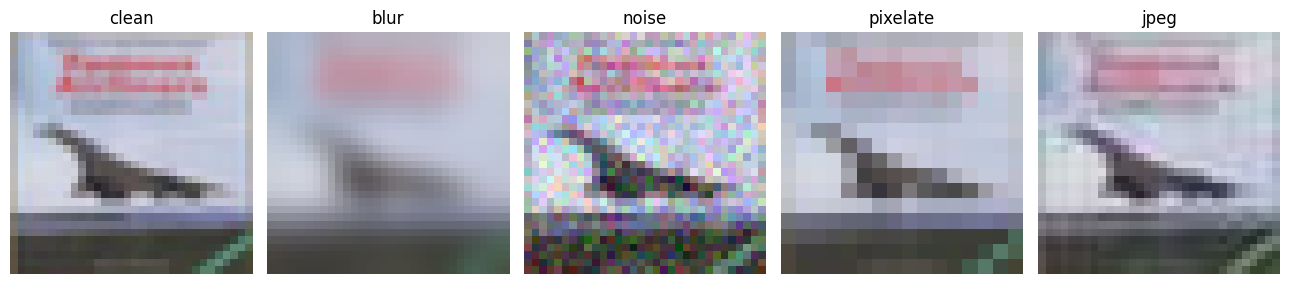

In [3]:
img = cifar_test.data[3]
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 5, figsize=(13, 3))
ax[0].imshow(img); ax[0].set_title("clean")
for a, f in zip(ax[1:], FAULTS):
    a.imshow(apply_fault(img, f, rng)); a.set_title(f)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Severity range per fault
The same image with the weakest and the strongest parameter value the recipe can draw.

| fault | parameter | mild | strong |
|---|---|---|---|
| blur | Gaussian sigma | 0.6 | 2.5 |
| noise | Gaussian std (0-255 scale) | 8 | 50 |
| pixelate | down-up factor | 2 | 4 |
| jpeg | quality | 70 | 8 |

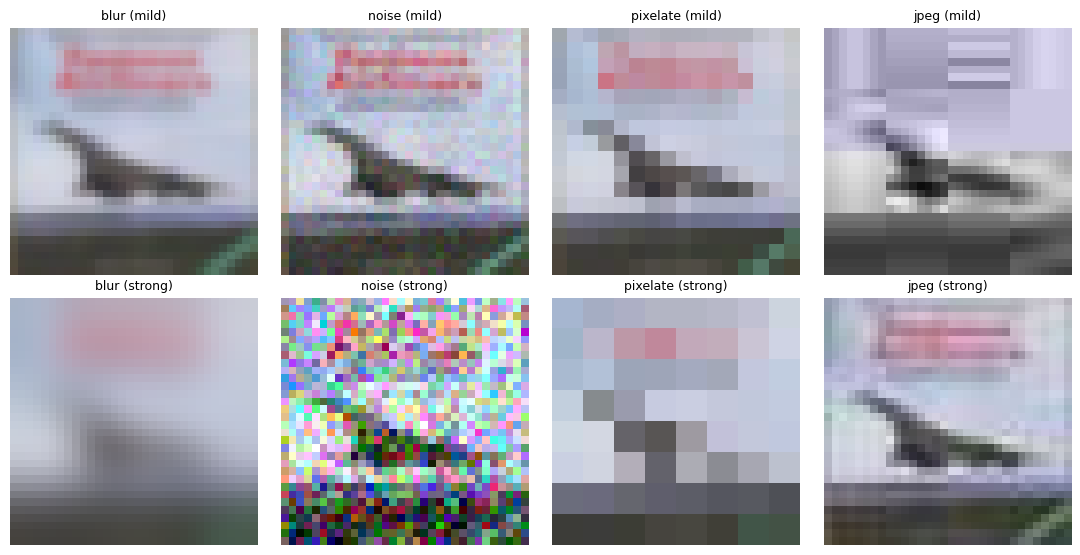

In [4]:
class FixedRng:  # deterministic stand-in: always returns the requested extreme
    def __init__(self, lo): self.lo = lo
    def uniform(self, a, b): return a if self.lo else b
    def normal(self, m, s, shape): return np.random.default_rng(0).normal(m, s, shape)
    def integers(self, a, b): return a if self.lo else b - 1
fig, ax = plt.subplots(2, 4, figsize=(11, 5.6))
for j, f in enumerate(FAULTS):
    for i, lo in enumerate([True, False]):
        ax[i, j].imshow(apply_fault(img, f, FixedRng(lo)))
        ax[i, j].set_title(f"{f} ({'mild' if lo else 'strong'})", fontsize=9); ax[i, j].axis("off")
plt.tight_layout(); plt.show()

### Full training samples: global or local, one to three faults, with the YOLO boxes
`make_sample` (in `visiondev/tagger/recipe.py`) is what builds the training set. 25% of images stay clean (no label, so YOLO learns to say
nothing). Each fault is global (box = whole image) or local (a 12-28 px patch, box = the patch). Stacked faults
are applied in the order pixelate, blur, noise, jpeg.

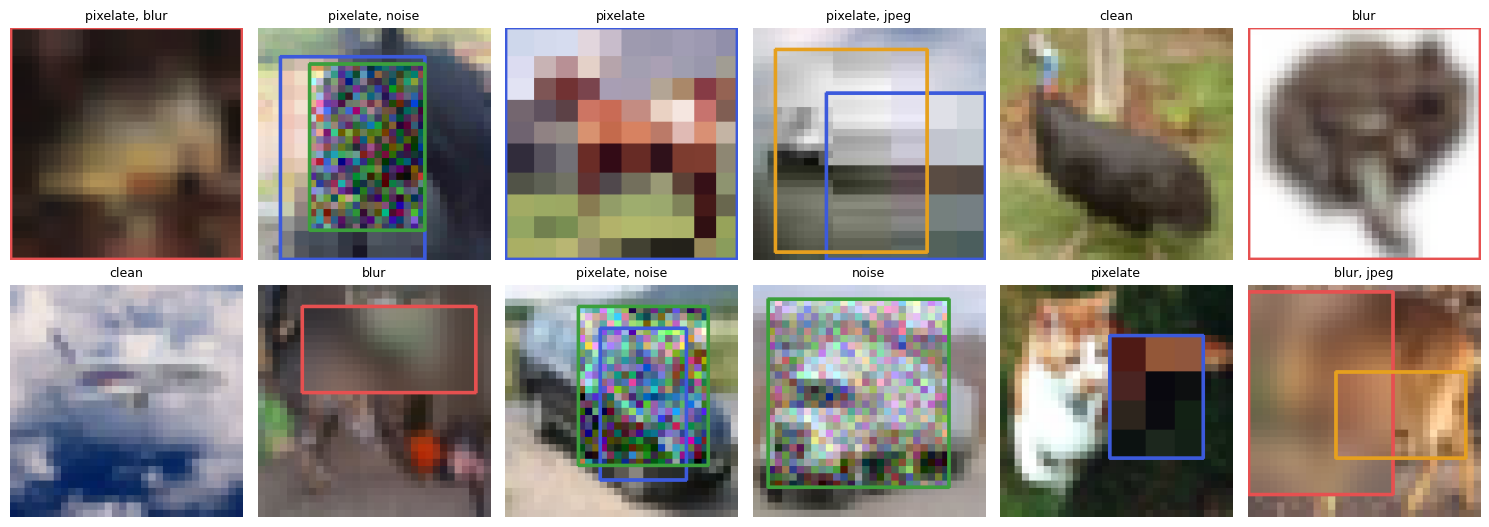

In [5]:
def draw(im, labels, scale=6):
    big = cv2.resize(im, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST).copy()
    H, W = big.shape[:2]
    for c, cx, cy, w, h in labels:
        x0, y0, x1, y1 = [int(v) for v in ((cx - w/2) * W, (cy - h/2) * H, (cx + w/2) * W, (cy + h/2) * H)]
        cv2.rectangle(big, (x0, y0), (x1 - 1, y1 - 1), COLORS[FAULTS[c]], 2)
    return big
rng = np.random.default_rng(11)
fig, ax = plt.subplots(2, 6, figsize=(15, 5.4))
for a in ax.ravel():
    im, lab = make_sample(cifar_test.data[int(rng.integers(0, 10000))], rng)
    a.imshow(draw(im, lab)); a.axis("off")
    a.set_title(", ".join(FAULTS[l[0]] for l in lab) or "clean", fontsize=9)
plt.tight_layout(); plt.show()

### The bug in the original recipe (why noise was never learned)
The original notebook added noise with `astype(np.uint8)`. Negative noise wraps around to values near 255, so
half of every noisy patch turned **white** instead of grainy. The v2 recipe does signed arithmetic and clips.

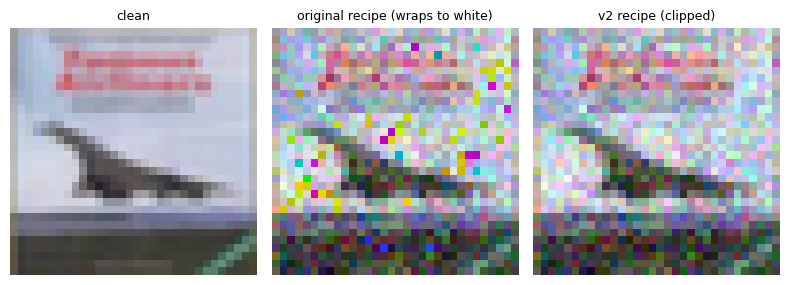

In [6]:
patch = cifar_test.data[3].copy()
n = np.random.default_rng(0).normal(0, 25, patch.shape)
old = (patch.astype(np.float32) + n).astype(np.uint8)            # original: wraps around
new = np.clip(patch.astype(np.float32) + n, 0, 255).astype(np.uint8)  # v2: clip
fig, ax = plt.subplots(1, 3, figsize=(8, 2.9))
for a, im, t in zip(ax, [patch, old, new], ["clean", "original recipe (wraps to white)", "v2 recipe (clipped)"]):
    a.imshow(im); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 2. The training set
24,000 training and 3,000 validation images, built from the **CIFAR-10 train split only**. The CIFAR test
split is never used for training, so every accuracy number below is on unseen images.
Built by `python -m visiondev.tagger.make_dataset`. Counts of the dataset used for the reported run (an image can contain several faults, so the `has_` columns do not add up to `images`):

In [7]:
pd.DataFrame(json.loads((RES / "dataset_stats.json").read_text())).T

,images,clean,has_blur,has_noise,has_pixelate,has_jpeg,boxes
train,24000,5941,6719,6627,6575,6635,26556
val,3000,771,800,828,865,781,3274


## 3. Training run

```bash
python -m visiondev.tagger.make_dataset --cifar-root ./data --out outputs/tagger_dataset
PYTORCH_ENABLE_MPS_FALLBACK=1 python -m visiondev.tagger.train --data outputs/tagger_dataset/data.yaml --device mps --epochs 40
```

| setting | value |
|---|---|
| model | YOLO11n architecture, trained **from scratch** (no pretrained weights) |
| input size | 64 (CIFAR images are 32x32, upscaled 2x) |
| epochs / batch | 40 / 128 |
| geometric augmentation | **off** (mosaic, scale, translate, rotate, shear, perspective, mixup). They resample pixels, which would blur or alias the very faults being learned |
| kept | horizontal flip, colour jitter |
| hardware | Apple M-series GPU (MPS), about 55 s per epoch when nothing else is running |

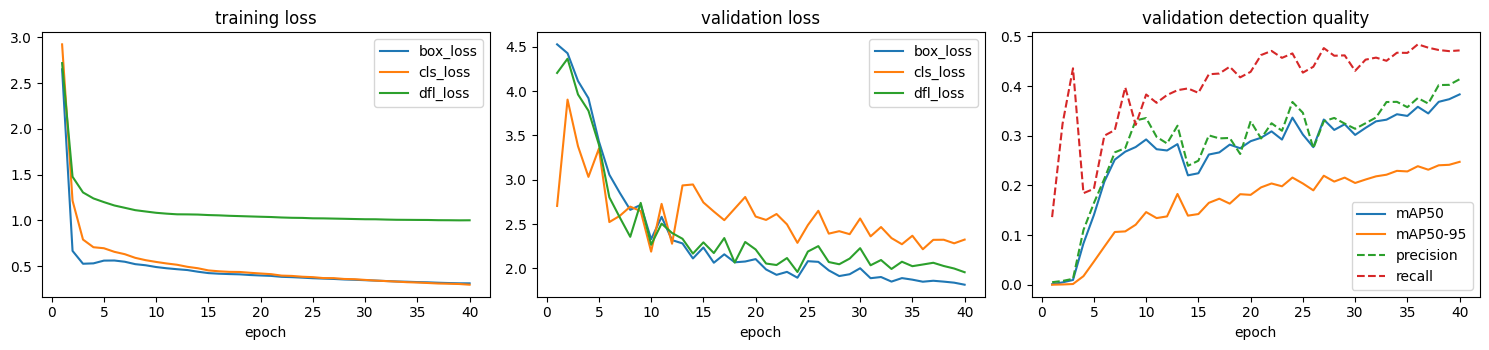

epochs run: 40 | total train time: 98 min
best epoch 40: mAP50=0.383  mAP50-95=0.248  P=0.414  R=0.472


In [8]:
r = pd.read_csv(RES / "results.csv"); r.columns = [c.strip() for c in r.columns]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k in ["train/box_loss", "train/cls_loss", "train/dfl_loss"]: ax[0].plot(r.epoch, r[k], label=k.split("/")[1])
ax[0].set_title("training loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
for k in ["val/box_loss", "val/cls_loss", "val/dfl_loss"]: ax[1].plot(r.epoch, r[k], label=k.split("/")[1])
ax[1].set_title("validation loss"); ax[1].legend(); ax[1].set_xlabel("epoch")
ax[2].plot(r.epoch, r["metrics/mAP50(B)"], label="mAP50"); ax[2].plot(r.epoch, r["metrics/mAP50-95(B)"], label="mAP50-95")
ax[2].plot(r.epoch, r["metrics/precision(B)"], "--", label="precision"); ax[2].plot(r.epoch, r["metrics/recall(B)"], "--", label="recall")
ax[2].set_title("validation detection quality"); ax[2].legend(); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()
b = r.loc[r["metrics/mAP50(B)"].idxmax()]
print(f"epochs run: {int(r.epoch.max())} | total train time: {r.time.max()/60:.0f} min")
print(f"best epoch {int(b.epoch)}: mAP50={b['metrics/mAP50(B)']:.3f}  mAP50-95={b['metrics/mAP50-95(B)']:.3f}  P={b['metrics/precision(B)']:.3f}  R={b['metrics/recall(B)']:.3f}")

The box-level mAP (about 0.38) is modest, and that is expected: for a **global** fault the "box" is the whole
image, and for a local fault the exact patch edges are hard to see at 32 px. What matters for VisionDev is
whether the right fault *name* is reported, which section 4 measures directly.

## 4. Accuracy: old tagger vs new tagger

Four tests, all on CIFAR-10 **test** images. A detection counts as a tag when its confidence is at least 0.25.

* **A. Held-out recipe test**: 1,000 test images with injections from the v2 recipe (25% clean, 1-3 faults). Per-fault precision, recall, F1.
* **B. Dose-response**: a **different** injection recipe (PIL-based, global, five severities per fault). Checks that the tagger generalises beyond the recipe it was trained on.
* **C. Failed vs correct**: do CIFAR images the CNN gets wrong carry more fault tags than the ones it gets right? (1,500 vs 1,500, same indices as the earlier probe.)
* **D. Stored failures re-tagged**: the 4,821 failures logged by the original VisionDev run.

In [9]:
old = json.loads((RES / "eval_old.json").read_text()); new = json.loads((RES / "eval_new.json").read_text())
A = pd.DataFrame({f: {"old recall": old["A_heldout_recipe"]["per_fault"][f]["recall"],
                      "new precision": new["A_heldout_recipe"]["per_fault"][f]["precision"],
                      "new recall": new["A_heldout_recipe"]["per_fault"][f]["recall"],
                      "new F1": new["A_heldout_recipe"]["per_fault"][f]["f1"]} for f in FAULTS}).T
print("TEST A: held-out recipe, 1000 images"); display(A)
a = new["A_heldout_recipe"]
print(f"clean images correctly left untagged: old {old['A_heldout_recipe']['clean_specificity(no detection)']:.1%}  new {a['clean_specificity(no detection)']:.1%}")
print(f"exact tag-set match: single-fault images {a['exact_set_match']['single']:.1%}, images with 2+ faults {a['exact_set_match']['mixed']:.1%}")

TEST A: held-out recipe, 1000 images


,old recall,new precision,new recall,new F1
blur,0.014,0.960,0.910,0.935
noise,0.000,0.980,0.941,0.960
pixelate,0.000,0.975,0.901,0.937
jpeg,0.029,0.985,0.954,0.969


clean images correctly left untagged: old 98.8%  new 97.6%
exact tag-set match: single-fault images 97.3%, images with 2+ faults 73.2%


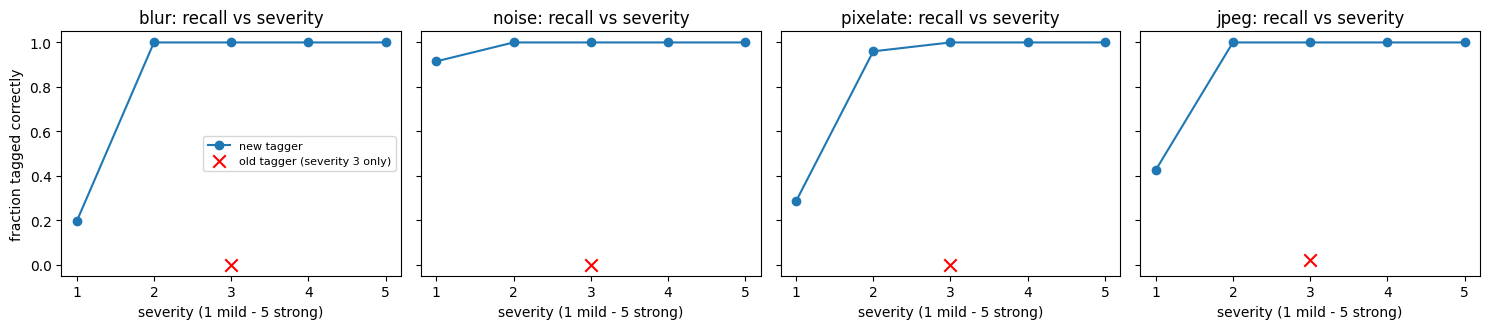

TEST B: new tagger recall by severity (PIL recipe, 200 images each)


,sev 1,sev 2,sev 3,sev 4,sev 5
blur,0.195,1.00,1.0,1.0,1.0
noise,0.915,1.00,1.0,1.0,1.0
pixelate,0.285,0.96,1.0,1.0,1.0
jpeg,0.425,1.00,1.0,1.0,1.0


old tagger at severity 3: {'blur': 0.0, 'noise': 0.0, 'pixelate': 0.0, 'jpeg': 0.02}


In [10]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for a_, f in zip(ax, FAULTS):
    lv = [1, 2, 3, 4, 5]
    nr = [new["B_dose_response"][f"{f}@{L}"]["recall"] for L in lv]
    a_.plot(lv, nr, "o-", label="new tagger")
    if f"{f}@3" in old["B_dose_response"]:
        a_.scatter([3], [old["B_dose_response"][f"{f}@3"]["recall"]], c="r", marker="x", s=80, label="old tagger (severity 3 only)")
    a_.set_title(f"{f}: recall vs severity"); a_.set_xlabel("severity (1 mild - 5 strong)"); a_.set_ylim(-0.05, 1.05)
ax[0].set_ylabel("fraction tagged correctly"); ax[0].legend(fontsize=8, loc="center right")
plt.tight_layout(); plt.show()
B = pd.DataFrame({f: {f"sev {L}": new["B_dose_response"][f"{f}@{L}"]["recall"] for L in [1,2,3,4,5]} for f in FAULTS}).T
print("TEST B: new tagger recall by severity (PIL recipe, 200 images each)"); display(B)
print("old tagger at severity 3:", {f: old["B_dose_response"][f"{f}@3"]["recall"] for f in FAULTS})

In [11]:
C = pd.DataFrame({
    "old: failed": {t: old["C_failed_vs_correct"]["tags"][t]["failed_rate"] for t in FAULTS + ["none"]},
    "old: correct": {t: old["C_failed_vs_correct"]["tags"][t]["correct_rate"] for t in FAULTS + ["none"]},
    "new: failed": {t: new["C_failed_vs_correct"]["tags"][t]["failed_rate"] for t in FAULTS + ["none"]},
    "new: correct": {t: new["C_failed_vs_correct"]["tags"][t]["correct_rate"] for t in FAULTS + ["none"]},
    "new: p-value": {t: new["C_failed_vs_correct"]["tags"][t]["p_value"] for t in FAULTS + ["none"]}})
print("TEST C: tag rate on clean CIFAR images the CNN got wrong vs right (1500 each)"); display(C)

TEST C: tag rate on clean CIFAR images the CNN got wrong vs right (1500 each)


,old: failed,old: correct,new: failed,new: correct,new: p-value
blur,0.001,0.003,0.019,0.023,0.5211
noise,0.000,0.000,0.004,0.004,1.0000
pixelate,0.000,0.000,0.000,0.001,0.4794
jpeg,0.003,0.007,0.010,0.021,0.0187
none,0.996,0.991,0.967,0.951,0.0335


In [12]:
D = new["D_stored_failures"]
print("TEST D: the 4,821 stored failures re-tagged by the new tagger")
print("any fault flagged:", f"{D['any_fault_flagged']:.1%}")
print("top tag (unique images):", D["new_top_tag_unique"])
ct = pd.DataFrame(D["crosstab_old_to_new"]).fillna(0).astype(int).T
ct.index.name = "old tag"; ct.columns.name = "new top tag"; display(ct)

TEST D: the 4,821 stored failures re-tagged by the new tagger
any fault flagged: 3.7%
top tag (unique images): {'none': 4642, 'jpeg': 62, 'noise': 20, 'blur': 96, 'pixelate': 1}


new top tag,none,jpeg,noise,blur,pixelate
old tag,,,,,
blur,2300,25,8,49,0
jpeg,1414,27,6,28,1
noise,126,3,1,4,0
pixelate,802,7,5,15,0


## 5. Inference examples

The real model on CIFAR **test** images (not seen in training). Boxes are the detections at confidence >= 0.25,
labelled with the fault and its confidence.

In [13]:
model = YOLO(str(WEIGHTS))
def predict(im, conf=0.25):
    r = model.predict(im[:, :, ::-1].copy(), imgsz=64, conf=conf, verbose=False, device="cpu")[0]
    return [(model.names[int(c)], float(s), b.tolist()) for c, s, b in zip(r.boxes.cls, r.boxes.conf, r.boxes.xyxy)]
def show(ims, titles, ncols=6, scale=6, truths=None):
    n = len(ims); nrows = (n + ncols - 1) // ncols
    fig, ax = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 3 * nrows)); ax = np.atleast_1d(ax).ravel()
    for k, a in enumerate(ax):
        a.axis("off")
        if k >= n: continue
        big = cv2.resize(ims[k], None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST).copy()
        dets = predict(ims[k])
        for name, s, (x0, y0, x1, y1) in dets:
            cv2.rectangle(big, (int(x0*scale), int(y0*scale)), (int(x1*scale) - 1, int(y1*scale) - 1), COLORS[name], 2)
        a.imshow(big)
        txt = ", ".join(f"{n_} {s:.2f}" for n_, s, _ in dets) or "no fault"
        a.set_title(f"{titles[k]}\n-> {txt}", fontsize=8)
    plt.tight_layout(); plt.show()

### 5a. One image per case (clean, each single fault, a mixed case)

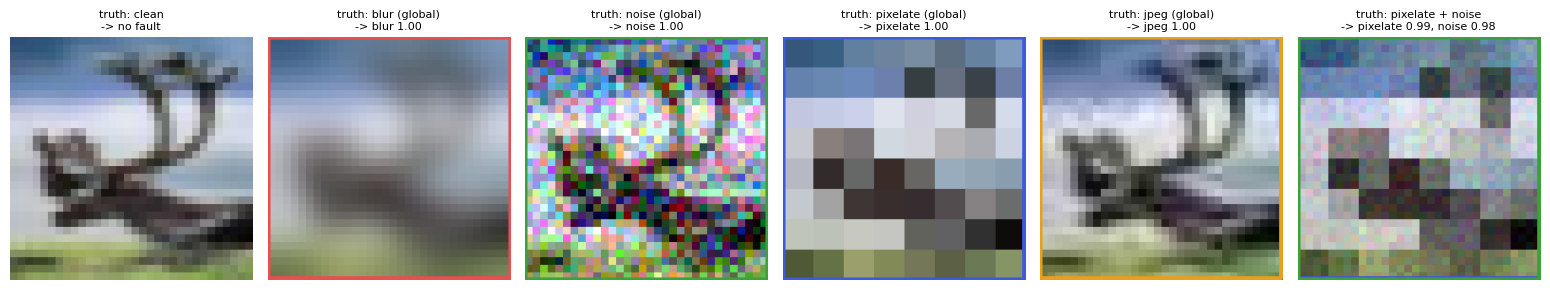

In [14]:
rng = np.random.default_rng(5)
base = cifar_test.data[40]
ims, titles = [base.copy()], ["truth: clean"]
for f in FAULTS:
    ims.append(apply_fault(base, f, rng)); titles.append(f"truth: {f} (global)")
mixed = apply_fault(apply_fault(base, "pixelate", rng), "noise", rng)
ims.append(mixed); titles.append("truth: pixelate + noise")
show(ims, titles, ncols=6)

### 5b. Random held-out samples from the training recipe (truth in the title)

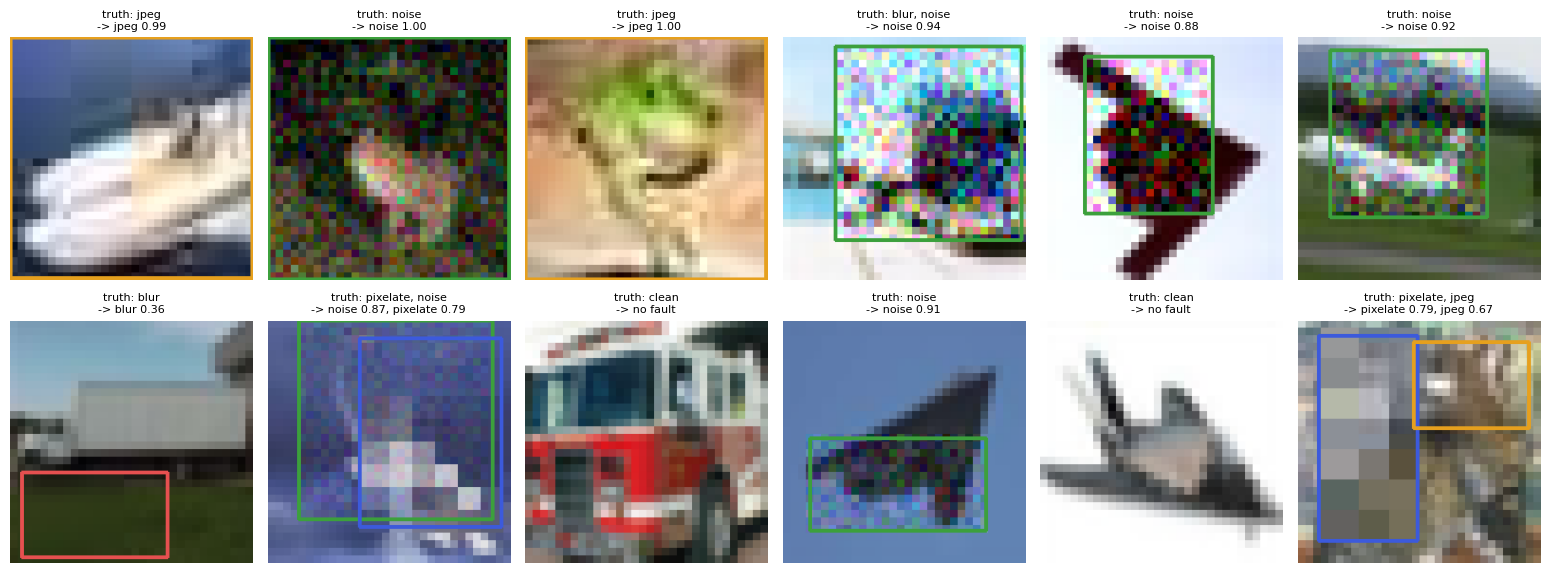

In [15]:
rng = np.random.default_rng(77); ims, titles = [], []
for i in np.random.default_rng(1).choice(10000, 12, replace=False):
    im, lab = make_sample(cifar_test.data[int(i)], rng)
    ims.append(im); titles.append("truth: " + (", ".join(FAULTS[l[0]] for l in lab) or "clean"))
show(ims, titles, ncols=6)

### 5c. Dose strip: blur and noise from mild to strong (PIL recipe, not the training recipe)

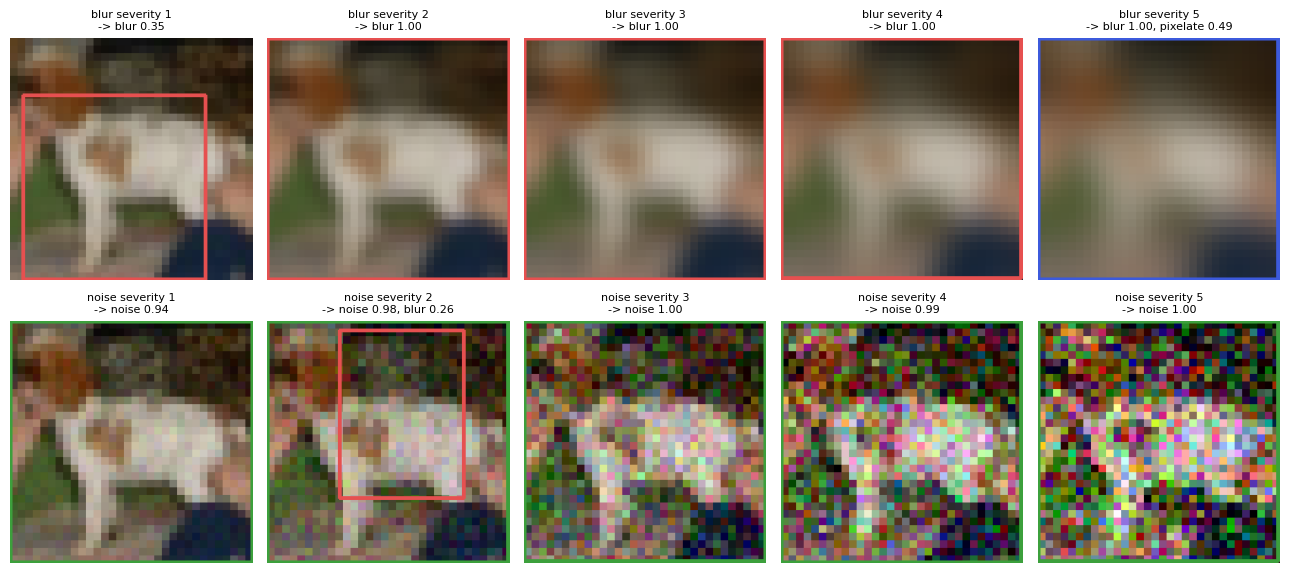

In [16]:
from PIL import Image, ImageFilter
DOSE = {"blur": [0.5, 1.0, 1.5, 2.0, 2.5], "noise": [0.02, 0.05, 0.10, 0.15, 0.20]}
base = Image.fromarray(cifar_test.data[12]); ims, titles = [], []
for f, lv in DOSE.items():
    for L, v in enumerate(lv, 1):
        if f == "blur": im = np.asarray(base.filter(ImageFilter.GaussianBlur(v)))
        else: im = (np.clip(np.asarray(base, dtype=np.float32) / 255 + np.random.default_rng(L).normal(0, v, (32, 32, 3)), 0, 1) * 255).round().astype(np.uint8)
        ims.append(im); titles.append(f"{f} severity {L}")
show(ims, titles, ncols=5)

## 6. What the results do and do not say

**The tagger itself works.**
* Test A (held-out, unseen CIFAR test images): recall 90-95% per fault with precision 96-99%; 97.6% of clean images
  correctly get no tag; single-fault images get exactly the right tag set 97% of the time, images with two or more faults 73%.
* Test B (a different injection recipe): 96-100% recall from severity 2 upward. It is weakest at severity 1
  (the faintest dose), where it often says "none"; pixelate at low severity is sometimes read as jpeg.
* The old tagger scored 0-3% recall on the same images. The retraining fixed that completely.

**It does not explain why the CNN fails on clean CIFAR images.**
* Test C: images the CNN gets wrong are not more likely to carry a fault tag than images it gets right
  (blur, noise, pixelate: p > 0.4; jpeg is, if anything, slightly less common among failures).
* Test D: about 96% of the 4,821 stored failures get no fault tag from the new tagger. The earlier tags
  (mostly blur, jpeg, pixelate) came from the old tagger guessing on images it could not read.
* Natural failures on clean CIFAR are therefore mostly something else: semantic confusion (cat/dog, truck/car),
  label noise, or model capacity. This tagger is useful where an image really is degraded; it should not
  be presented as the cause of failure on clean data.

**Known limits**
* Tagging is trained on synthetic faults. Real camera blur, sensor noise and recompression look different
  and have not been tested.
* Mixed-fault images are the weak spot (73% exact match).
* Box accuracy (mAP50-95 0.25) is low; use the fault name, not the box.